# 02 — Làm sạch dữ liệu

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
PROC = ROOT / 'data' / 'processed'

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

In [6]:
df = pd.read_csv(RAW / 'datadone.csv')
df_raw = df.copy()

print(f'Kích thước dữ liệu gốc: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột')
display(df.head())

Kích thước dữ liệu gốc: 40598 dòng, 21 cột


,Local Time,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Temperature,Relative Humidity,Precipitation,Clouds,Pressure,UV Index,Wind Speed,Wind Direction,Solar Radiation
0,2022-01-13 00:00:00,2022-01-12T17:00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,158,381.300,16.700,86.700,109.100,65.700,54.700,17.000,93,0.000,100,1019,0.000,1.600,106,0
1,2022-01-13 01:00:00,2022-01-12T18:00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,159,389.800,17.000,87.000,110.800,66.700,59.000,16.800,97,0.000,100,1019,0.000,1.200,98,0
2,2022-01-13 02:00:00,2022-01-12T19:00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,158,385.000,16.000,87.300,107.100,63.700,58.700,16.400,97,0.000,91,1019,0.000,1.200,78,0
3,2022-01-13 03:00:00,2022-01-12T20:00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,157,380.100,15.000,87.700,103.500,61.600,58.300,16.100,97,0.000,83,1019,0.000,1.200,58,0
4,2022-01-13 04:00:00,2022-01-12T21:00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,156,375.300,14.000,88.000,99.800,59.600,58.000,15.700,97,0.000,75,1018,0.000,1.600,46,0


In [7]:
df['Local Time'] = pd.to_datetime(df['Local Time'], errors='coerce')
df['UTC Time'] = pd.to_datetime(df['UTC Time'], utc=True, errors='coerce')

df = df.sort_values('Local Time').reset_index(drop=True)

print('Bắt đầu:', df['Local Time'].min())
print('Kết thúc:', df['Local Time'].max())
print('Số dòng:', len(df))
print('\nCác cột:')
print(df.columns.tolist())


Bắt đầu: 2022-01-13 00:00:00
Kết thúc: 2026-08-31 23:00:00
Số dòng: 40598

Các cột:
['Local Time', 'UTC Time', 'City', 'Country Code', 'Timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Temperature', 'Relative Humidity', 'Precipitation', 'Clouds', 'Pressure', 'UV Index', 'Wind Speed', 'Wind Direction', 'Solar Radiation']


## 2.1 Kiểm tra Local Time và UTC Time

In [8]:

utc_to_local = ( df['UTC Time'].dt.tz_convert('Asia/Ho_Chi_Minh').dt.tz_localize(None))

time_diff = (df['Local Time'] - utc_to_local).dt.total_seconds() / 3600

print('Số dòng kiểm tra được:', time_diff.notna().sum())
print('Số dòng Local Time khớp UTC Time:', (time_diff == 0).sum())
print('Số dòng không khớp:', (time_diff != 0).sum())
print('\nPhân bố chênh lệch (giờ):')
display(time_diff.value_counts(dropna=False).head(10))


Số dòng kiểm tra được: 40598
Số dòng Local Time khớp UTC Time: 40598
Số dòng không khớp: 0

Phân bố chênh lệch (giờ):


0.000    40598
Name: count, dtype: int64

# III. Chất lượng và độ liên tục của dữ liệu

## 3.1 Missing value và timestamp trùng

In [9]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    'Số giá trị thiếu': missing,
    'Tỷ lệ (%)': missing / len(df) * 100
})

display(missing_table.round(4))

duplicate_mask = df.duplicated(subset='Local Time', keep=False)

print('Số dòng có timestamp trùng:', duplicate_mask.sum())
print('Số timestamp bị trùng:', df.loc[duplicate_mask, 'Local Time'].nunique())


,Số giá trị thiếu,Tỷ lệ (%)
CO,74,0.182
NO2,74,0.182
O3,74,0.182
SO2,74,0.182
PM10,2,0.005
PM25,2,0.005


Số dòng có timestamp trùng: 16
Số timestamp bị trùng: 8


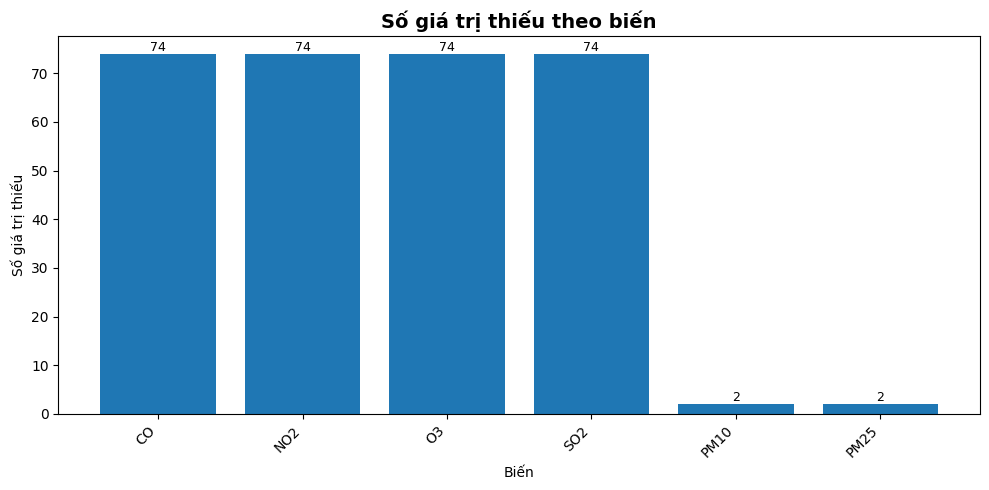

In [10]:
if len(missing_table) > 0:
    plt.figure(figsize=(10, 5))
    bars = plt.bar(missing_table.index, missing_table['Số giá trị thiếu'])
    plt.title('Số giá trị thiếu theo biến', fontsize=14, fontweight='bold')
    plt.xlabel('Biến')
    plt.ylabel('Số giá trị thiếu')
    plt.xticks(rotation=45, ha='right')

    for bar in bars:
        value = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value,
            f'{int(value)}',
            ha='center',
            va='bottom',
            fontsize=9
        )

    plt.tight_layout()
    plt.show()
else:
    print('Không có giá trị thiếu.')


In [11]:
# Phân biệt trùng toàn bộ dòng với trùng riêng mốc thời gian
n_duplicate_rows = int(df.duplicated().sum())
n_duplicate_times = int(df['Local Time'].duplicated().sum())

print('Số dòng trùng hoàn toàn:', n_duplicate_rows)
print('Số mốc Local Time bị lặp (không tính bản đầu):', n_duplicate_times)

if n_duplicate_times > 0:
    print('\n Các mốc Local Time bị lặp:')
    duplicated_examples = df[df.duplicated(subset='Local Time', keep=False)]
    display(duplicated_examples.head(12))

Số dòng trùng hoàn toàn: 8
Số mốc Local Time bị lặp (không tính bản đầu): 8

 Các mốc Local Time bị lặp:


,Local Time,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Temperature,Relative Humidity,Precipitation,Clouds,Pressure,UV Index,Wind Speed,Wind Direction,Solar Radiation
207,2022-01-21 15:00:00,2022-01-21 08:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,115,282.900,9.000,94.700,74.600,44.500,23.000,17.100,94,0.250,87,1013,1.200,1.330,245,205
208,2022-01-21 15:00:00,2022-01-21 08:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,115,282.900,9.000,94.700,74.600,44.500,23.000,17.100,94,0.250,87,1013,1.200,1.330,245,205
7128,2022-11-06 00:00:00,2022-11-05 17:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,146,370.000,64.000,1.700,74.800,49.500,148.000,22.200,88,0.000,1,1018,0.000,1.660,140,0
7129,2022-11-06 00:00:00,2022-11-05 17:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,146,370.000,64.000,1.700,74.800,49.500,148.000,22.200,88,0.000,1,1018,0.000,1.660,140,0
8030,2022-12-13 13:00:00,2022-12-13 06:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,151,159.300,8.000,129.000,84.800,56.600,85.000,22.000,23,0.000,14,1017,5.100,2.000,360,712
8031,2022-12-13 13:00:00,2022-12-13 06:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,151,159.300,8.000,129.000,84.800,56.600,85.000,22.000,23,0.000,14,1017,5.100,2.000,360,712
11969,2023-05-26 19:00:00,2023-05-26 12:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,85,124.300,31.000,48.000,48.200,32.200,38.000,30.500,74,0.000,62,1007,0.000,3.000,160,0
11970,2023-05-26 19:00:00,2023-05-26 12:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,85,124.300,31.000,48.000,48.200,32.200,38.000,30.500,74,0.000,62,1007,0.000,3.000,160,0
22270,2024-07-29 01:00:00,2024-07-28 18:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,103,157.000,36.000,34.500,41.100,32.400,4.000,29.500,92,0.000,100,1000,0.000,1.000,140,0
22271,2024-07-29 01:00:00,2024-07-28 18:00:00+00:00,Hoàn Kiếm,VN,Asia/Ho_Chi_Minh,103,157.000,36.000,34.500,41.100,32.400,4.000,29.500,92,0.000,100,1000,0.000,1.000,140,0


## 3.2 Missing timestamp và độ phủ theo năm

In [12]:
df_unique = df.dropna(subset=['Local Time']).drop_duplicates(subset='Local Time', keep='first').copy()

expected_time = pd.date_range(
    start=df_unique['Local Time'].min(),
    end=df_unique['Local Time'].max(),
    freq='h'
)
missing_time = expected_time.difference(pd.DatetimeIndex(df_unique['Local Time']))

print('Tổng mốc giờ kỳ vọng:', len(expected_time))
print('Tổng mốc giờ quan sát khác nhau:', len(df_unique))
print('Số mốc giờ bị thiếu:', len(missing_time))

if len(missing_time) > 0:
    display(pd.DataFrame({'Local Time bị thiếu': missing_time}))


Tổng mốc giờ kỳ vọng: 40608
Tổng mốc giờ quan sát khác nhau: 40590
Số mốc giờ bị thiếu: 18


,Local Time bị thiếu
0,2022-08-14 13:00:00
1,2023-01-09 17:00:00
2,2023-01-13 20:00:00
3,2023-02-14 21:00:00
4,2023-04-10 08:00:00
5,2023-05-29 07:00:00
6,2023-07-01 19:00:00
7,2024-09-20 17:00:00
8,2024-12-01 00:00:00
9,2025-03-23 17:00:00


,expected_hours,available_hours,missing_hours,coverage_%
year,,,,
2022,8472,8471,1,99.988
2023,8760,8754,6,99.932
2024,8784,8780,4,99.954
2025,8760,8756,4,99.954
2026,5832,5827,5,99.914


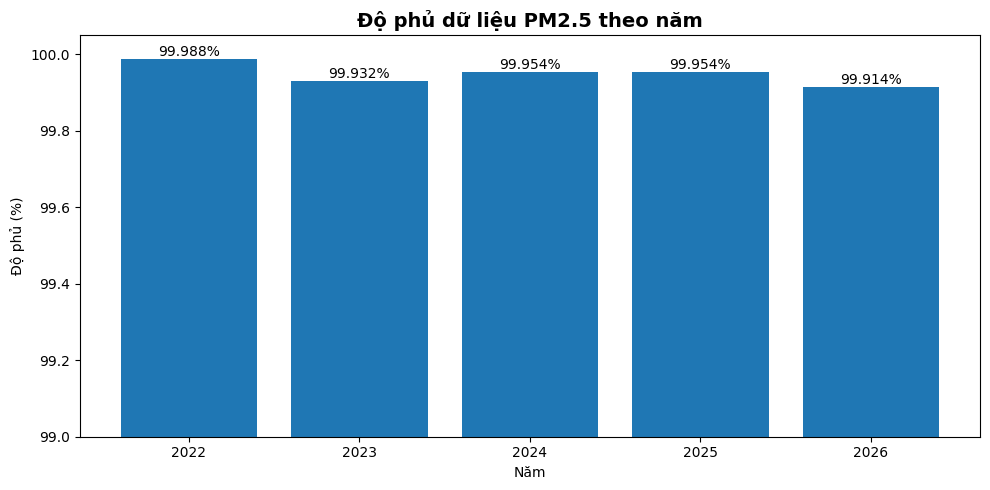

In [13]:
ts = (df_unique .set_index('Local Time') .asfreq('h'))

coverage = pd.DataFrame(index=ts.index)
coverage['has_pm25'] = ts['PM25'].notna().astype(int)
coverage['year'] = coverage.index.year

year_coverage = coverage.groupby('year').agg(expected_hours=('has_pm25', 'size'), available_hours=('has_pm25', 'sum'))

year_coverage['missing_hours'] = (year_coverage['expected_hours'] - year_coverage['available_hours'])

year_coverage['coverage_%'] = (year_coverage['available_hours'] / year_coverage['expected_hours'] * 100)

display(year_coverage.round(3))

plt.figure(figsize=(10, 5))
bars = plt.bar(year_coverage.index.astype(str), year_coverage['coverage_%'])

plt.title('Độ phủ dữ liệu PM2.5 theo năm', fontsize=14, fontweight='bold')
plt.xlabel('Năm')
plt.ylabel('Độ phủ (%)')
plt.ylim(99, 100.05)

for bar, val in zip(bars, year_coverage['coverage_%']):
    plt.text(bar.get_x() + bar.get_width()/2, val, f'{val:.3f}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

# IV. Khám phá biến mục tiêu PM2.5

## 4.1 Thống kê phân phối PM2.5

In [14]:
# Chỉ bỏ qua NaN trong phép thống kê không xóa dòng khỏi bộ dữ liệu gốc
pm25 = ts['PM25'].dropna()

print('Thống kê PM2.5 (µg/m³):')
display(pm25.describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).to_frame('PM2.5'))

print('Số mốc PM2.5 >= 200 µg/m³:', int((pm25 >= 200).sum()))

Thống kê PM2.5 (µg/m³):


,PM2.5
count,40588.000
mean,43.333
std,32.608
min,1.000
5%,12.000
25%,23.000
50%,34.400
75%,52.500
95%,110.700
max,400.000


Số mốc PM2.5 >= 200 µg/m³: 143


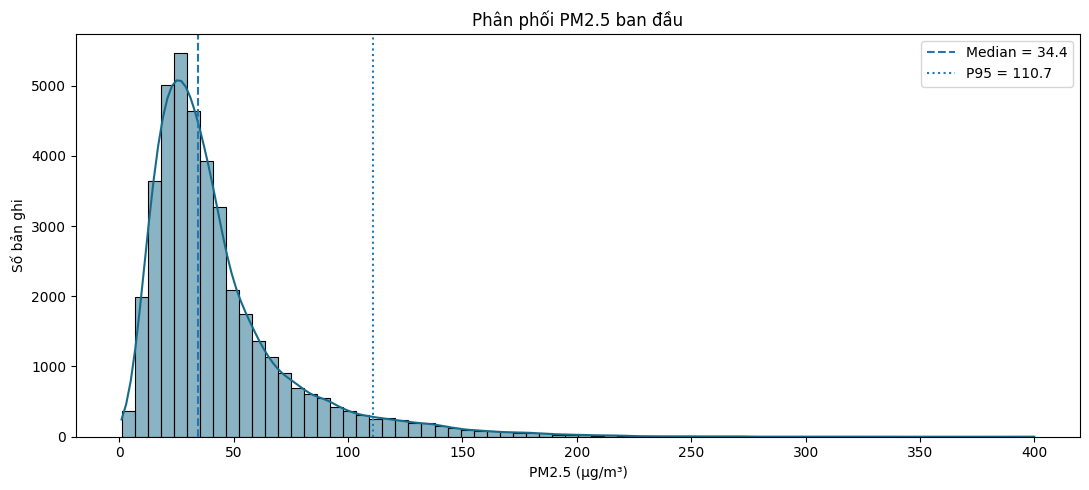

In [15]:
plt.figure(figsize=(11, 5))
sns.histplot(pm25, bins=70, kde=True, color='#176B8A')
plt.axvline(pm25.median(), linestyle='--', label=f'Median = {pm25.median():.1f}')
plt.axvline(pm25.quantile(0.95), linestyle=':', label=f'P95 = {pm25.quantile(0.95):.1f}')
plt.title('Phân phối PM2.5 ban đầu')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Số bản ghi')
plt.legend()
plt.tight_layout()
plt.show()


## 4.3. Những mốc PM2.5 cao nhất

In [16]:
peak_cols = [col for col in ['PM25', 'PM10', 'AQI', 'CO', 'NO2', 'O3', 'SO2'] if col in ts.columns]
peak_table = ts[peak_cols].sort_values('PM25', ascending=False).head(15)

print('15 mốc PM2.5 cao nhất:')
display(peak_table)

15 mốc PM2.5 cao nhất:


,PM25,PM10,AQI,CO,NO2,O3,SO2
Local Time,,,,,,,
2024-02-07 19:00:00,400.000,400.000,289.000,403.000,46.000,8.600,74.000
2025-03-20 23:00:00,390.900,452.600,500.000,10.000,24.000,2.700,4.000
2025-03-20 22:00:00,380.900,441.700,399.000,10.000,23.000,4.300,20.000
2023-12-14 03:00:00,355.500,368.000,279.000,202.000,62.000,13.000,58.000
2022-04-08 04:00:00,349.600,485.300,500.000,1663.800,65.000,12.000,97.000
2022-04-08 03:00:00,332.400,487.500,478.000,1522.200,64.700,17.300,107.300
2025-01-02 23:00:00,331.800,342.300,455.000,1210.000,15.000,2.200,32.000
2022-04-08 05:00:00,329.400,483.200,500.000,1677.300,53.700,16.700,81.000
2025-01-02 22:00:00,322.600,332.800,398.000,2117.000,15.000,1.100,32.000


# V. Những điểm nghi ngờ bất thường

In [17]:
# Rolling median và Z-score trên phần dư PM2.5
rolling_median = ts['PM25'].rolling(window=24, center=True, min_periods=6).median()
residual = ts['PM25'] - rolling_median

residual_std = residual.std()
if pd.notna(residual_std) and residual_std > 0:
    z_score = (residual - residual.mean()) / residual_std
else:
    z_score = pd.Series(np.nan, index=ts.index)

outlier_flag = (z_score.abs() > 3) & ts['PM25'].notna()

print('Số điểm nghi ngờ outlier (|z| > 3):', int(outlier_flag.sum()))

outlier_table = ts.loc[outlier_flag, ['PM25', 'PM10', 'AQI']].copy()
outlier_table['Rolling Median 24h'] = rolling_median.loc[outlier_flag]
outlier_table['Z-score'] = z_score.loc[outlier_flag]

print('15 điểm có |Z-score| cao nhất:')
display(outlier_table.reindex(z_score.loc[outlier_flag].abs().sort_values(ascending=False).index).head(15))

Số điểm nghi ngờ outlier (|z| > 3): 921
15 điểm có |Z-score| cao nhất:


,PM25,PM10,AQI,Rolling Median 24h,Z-score
Local Time,,,,,
2024-02-07 19:00:00,400.000,400.000,289.000,26.300,20.647
2023-12-14 03:00:00,355.500,368.000,279.000,72.500,15.612
2025-03-20 23:00:00,390.900,452.600,500.000,111.500,15.412
2025-03-20 22:00:00,380.900,441.700,399.000,111.500,14.857
2024-05-17 09:00:00,235.700,355.200,216.000,32.900,11.160
2025-06-24 17:00:00,230.900,267.400,245.000,30.500,11.027
2025-06-02 23:00:00,214.900,249.500,195.000,21.000,10.666
2024-04-28 02:00:00,243.800,326.200,230.000,51.100,10.600
2024-05-14 08:00:00,225.600,334.200,207.000,35.900,10.433


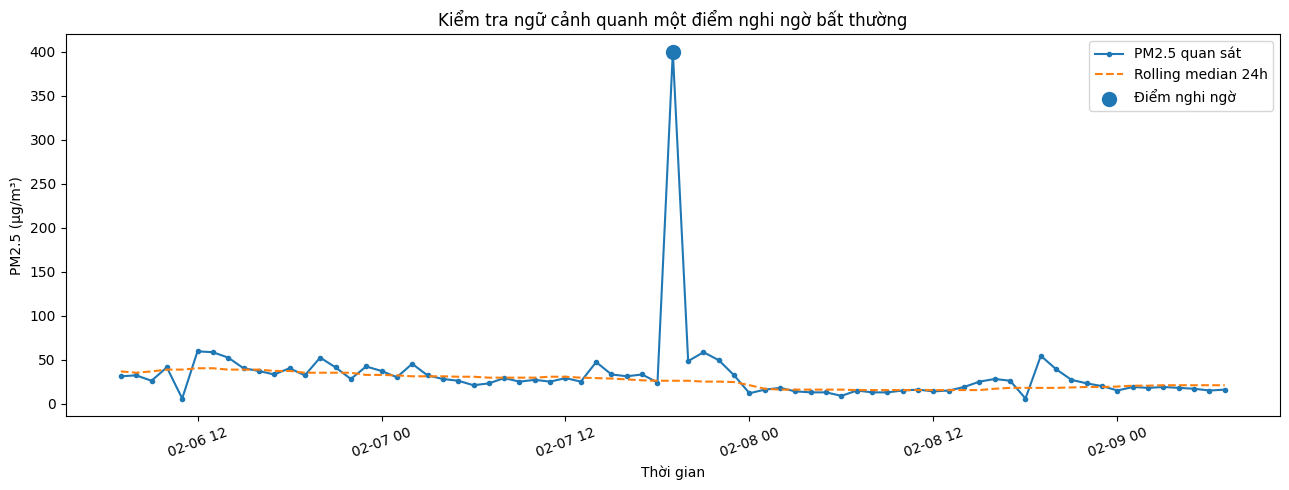

In [18]:
# Vẽ một đoạn thời gian xung quanh điểm nghi ngờ mạnh nhất
if outlier_flag.any():
    candidate_time = z_score.abs().idxmax()
    plot_start = candidate_time - pd.Timedelta(hours=36)
    plot_end = candidate_time + pd.Timedelta(hours=36)
    window_pm25 = ts.loc[plot_start:plot_end, 'PM25']
    window_median = rolling_median.loc[plot_start:plot_end]

    plt.figure(figsize=(13, 5))
    plt.plot(window_pm25.index, window_pm25, marker='.', label='PM2.5 quan sát')
    plt.plot(window_median.index, window_median, linestyle='--', label='Rolling median 24h')
    plt.scatter([candidate_time], [ts.loc[candidate_time, 'PM25']], s=100, label='Điểm nghi ngờ')
    plt.title('Kiểm tra ngữ cảnh quanh một điểm nghi ngờ bất thường')
    plt.xlabel('Thời gian')
    plt.ylabel('PM2.5 (µg/m³)')
    plt.xticks(rotation=20)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Không phát hiện điểm vượt ngưỡng Z-score khảo sát.')

# VI. Xử lý và làm sạch dữ liệu

In [19]:
df_unique = df.drop_duplicates().copy()
df_unique = df_unique.sort_values('Local Time').reset_index(drop=True)

print('Số dòng trước khi xóa:', len(df))
print('Số dòng sau khi xóa:', len(df_unique))
print('Số dòng đã xóa:', len(df) - len(df_unique))
print('Timestamp còn bị trùng:', int(df_unique['Local Time'].duplicated().sum()))

print('Timestamp có còn bị trùng sau khi làm sạch:', int(df_unique['Local Time'].duplicated().sum()))

Số dòng trước khi xóa: 40598
Số dòng sau khi xóa: 40590
Số dòng đã xóa: 8
Timestamp còn bị trùng: 0
Timestamp có còn bị trùng sau khi làm sạch: 0


In [20]:
clean = df_unique.set_index('Local Time').sort_index().reindex(expected_time)

# Cờ 1 = giờ đã được bổ sung, 0 = giờ có trong CSV gốc
# So với mốc giờ thật trong CSV gốc. df_unique đã reset_index nên index của nó chỉ là số thứ tự 0, 1, 2...
original_times = pd.DatetimeIndex(df_unique['Local Time'])
clean['Missing Hour (Inserted)'] = (~clean.index.isin(original_times)).astype('int8')
assert int(clean['Missing Hour (Inserted)'].sum()) == len(missing_time), 'Số giờ chèn thêm không khớp số giờ thiếu'

print('Kích thước sau khi khôi phục trục giờ:', clean.shape)
print('Số giờ mới thêm:', int(clean['Missing Hour (Inserted)'].sum()))
print('Các hàng mới thêm:')
display(clean.loc[missing_time].head(10))

Kích thước sau khi khôi phục trục giờ: (40608, 21)
Số giờ mới thêm: 18
Các hàng mới thêm:


,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Temperature,Relative Humidity,Precipitation,Clouds,Pressure,UV Index,Wind Speed,Wind Direction,Solar Radiation,Missing Hour (Inserted)
2022-08-14 13:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-01-09 17:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-01-13 20:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-02-14 21:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-04-10 08:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-05-29 07:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2023-07-01 19:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2024-09-20 17:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2024-12-01 00:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2025-03-23 17:00:00,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [21]:
# Chỉ điền metadata nếu toàn bộ bản ghi gốc thống nhất
for col in ['City', 'Country Code', 'Timezone']:
    unique_values = clean[col].dropna().unique()
    if len(unique_values) != 1:
        raise ValueError(f'{col} có nhiều giá trị, không thể tự điền: {unique_values}')
    clean[col] = clean[col].fillna(unique_values[0])

# Kiểm tra timezone của địa điểm nghiên cứu
if clean['Timezone'].iloc[0] != 'Asia/Ho_Chi_Minh':
    raise ValueError('Timezone không phải Asia/Ho_Chi_Minh. Cần kiểm tra lại.')

# Tính UTC từ Local Time của giờ mới, không sửa UTC của giờ gốc
expected_utc = pd.Series(
    clean.index.tz_localize('Asia/Ho_Chi_Minh').tz_convert('UTC'),
    index=clean.index
)

# UTC hiện tại đang là datetime UTC; nếu có lệch thì dừng
utc_mismatch = clean['UTC Time'].notna() & clean['UTC Time'].ne(expected_utc)
if utc_mismatch.any():
    raise ValueError('Có UTC Time không khớp Local Time. Cần kiểm tra nguồn.')

clean['UTC Time'] = clean['UTC Time'].fillna(expected_utc)
print('Metadata đã phục hồi cho:', int(clean['Missing Hour (Inserted)'].sum()), 'mốc giờ')
print('UTC Time còn thiếu:', int(clean['UTC Time'].isna().sum()))

Metadata đã phục hồi cho: 18 mốc giờ
UTC Time còn thiếu: 0


# VII. Phân tích Missing Values sau khi khôi phục giờ

In [22]:
# So sánh NaN ở dữ liệu gốc với NaN sau khi tạo đủ trục thời gian
missing_after = clean[df_raw.columns.drop('Local Time')].isna().sum()
missing_before = df_raw[df_raw.columns.drop('Local Time')].isna().sum()
missing_table = pd.DataFrame({
    'Thiếu ban đầu': missing_before,
    'Thiếu sau cleaning': missing_after.reindex(missing_before.index, fill_value=0)
})
missing_table['Tỷ lệ thiếu sau (%)'] = missing_table['Thiếu sau cleaning'] / len(clean) * 100

print('Tổng ô NaN trong dữ liệu gốc:', int(missing_before.sum()))
print('Tổng ô NaN sau khôi phục trục giờ:', int(missing_after.sum()))
print('Số giờ PM2.5 không có quan trắc:', int(clean['PM25'].isna().sum()))
display(missing_table[missing_table[['Thiếu ban đầu', 'Thiếu sau cleaning']].sum(axis=1) > 0])

Tổng ô NaN trong dữ liệu gốc: 300
Tổng ô NaN sau khôi phục trục giờ: 588
Số giờ PM2.5 không có quan trắc: 20


,Thiếu ban đầu,Thiếu sau cleaning,Tỷ lệ thiếu sau (%)
AQI,0,18,0.044
CO,74,92,0.227
NO2,74,92,0.227
O3,74,92,0.227
PM10,2,20,0.049
PM25,2,20,0.049
SO2,74,92,0.227
Temperature,0,18,0.044
Relative Humidity,0,18,0.044
Precipitation,0,18,0.044


In [23]:
# Điền giá trị thiếu bằng giờ trước, tối đa 1 giờ
clean_ffill = clean.copy()
cols_ffill = ['Temperature', 'Relative Humidity', 'Precipitation',
              'Pressure', 'Wind Speed', 'Clouds', 'Wind Direction',
              "UV Index", 'PM10', 'CO', 'NO2', 'O3', 'SO2', "PM25", 'Solar Radiation']
missing_before = clean_ffill[cols_ffill].isna()

clean_ffill[cols_ffill] = clean_ffill[cols_ffill].ffill(limit=1)




In [24]:
clean_ffill.drop(columns=['Missing Hour (Inserted)'], inplace=True)
clean_ffill.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 40608 entries, 2022-01-13 00:00:00 to 2026-08-31 23:00:00
Freq: h
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   UTC Time           40608 non-null  datetime64[ns, UTC]
 1   City               40608 non-null  object             
 2   Country Code       40608 non-null  object             
 3   Timezone           40608 non-null  object             
 4   AQI                40590 non-null  float64            
 5   CO                 40608 non-null  float64            
 6   NO2                40608 non-null  float64            
 7   O3                 40608 non-null  float64            
 8   PM10               40608 non-null  float64            
 9   PM25               40608 non-null  float64            
 10  SO2                40608 non-null  float64            
 11  Temperature        40608 non-null  float64            
 12  Rel

In [25]:
PROC.mkdir(parents=True, exist_ok=True)
clean_ffill.to_csv(PROC / 'cleaned_data.csv', index=True, date_format='%Y-%m-%d %H:%M:%S', index_label='Local Time')
print('Đã lưu cleaned_data.csv:', clean_ffill.shape)

Đã lưu cleaned_data.csv: (40608, 20)
